# 채팅 강도 분석

두 대화에서 **ChatGPT의 답변 수와 글자 수**를 10분 단위로 집계합니다. 가로축은 실제 시간이며, 한국 시간(Asia/Seoul)으로 표시합니다. 답변이 없는 구간은 0으로 표시합니다.

글자 수는 JSON의 `text` 길이이며 인용문과 마크다운 표기도 포함됩니다. 이 지표는 ChatGPT 답변의 빈도와 분량을 보여줍니다.

필요한 패키지: `pandas`, `matplotlib` (미설치 시 `%pip install pandas matplotlib`). 아래 셀을 순서대로 실행하세요. 그래프는 `03_aftermath/02_python/chat_intensity.png`에 저장됩니다.

In [5]:
import json
from pathlib import Path
from zoneinfo import ZoneInfo

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

TIMEZONE = "Asia/Seoul"
BIN = "10min"  # "5min", "30min" 등으로 변경 가능
FILES = {
    "01_sketch": "01_sketch-writing/04_JSON/chat.json",
    "02_conversation": "02_conversation-writing/02_JSON/chat.json",
}
ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if all((p / filename).is_file() for filename in FILES.values())
)
OUTPUT_DIR = ROOT / "03_aftermath" / "02_python"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
rows = []
for name, filename in FILES.items():
    data = json.loads((ROOT / filename).read_text(encoding="utf-8"))
    for message in data["messages"]:
        if message["role"] == "assistant" and not message.get("alternative", False):
            rows.append({
                "conversation": name,
                "time": message["created_at"],
                "characters": len(message.get("text") or ""),
            })

df = pd.DataFrame(rows)
df["time"] = pd.to_datetime(df["time"], utc=True).dt.tz_convert(TIMEZONE)
df = df.sort_values("time")

activity = {
    name: group.set_index("time")["characters"].resample(BIN)
        .agg(["size", "sum"])
        .rename(columns={"size": "messages", "sum": "characters"})
    for name, group in df.groupby("conversation", sort=False)
}

In [7]:
summary = []
for name, group in df.groupby("conversation", sort=False):
    counts = activity[name]["messages"]
    summary.append({
        "대화": name,
        "시작 (한국 시간)": group["time"].min().strftime("%m-%d %H:%M"),
        "종료 (한국 시간)": group["time"].max().strftime("%m-%d %H:%M"),
        "ChatGPT 답변 수": len(group),
        "ChatGPT 답변 글자 수": group["characters"].sum(),
        "답변 간격 중앙값 (분)": round(
            group["time"].diff().dt.total_seconds().median() / 60, 2
        ),
        f"최대 답변 수 / {BIN}": counts.max(),
        "최다 답변 구간 시작": counts.idxmax().strftime("%m-%d %H:%M"),
    })

display(pd.DataFrame(summary).set_index("대화"))

,시작 (한국 시간),종료 (한국 시간),ChatGPT 답변 수,ChatGPT 답변 글자 수,답변 간격 중앙값 (분),최대 답변 수 / 10min,최다 답변 구간 시작
대화,,,,,,,
01_sketch,10-11 01:28,10-11 18:21,142,540979,2.82,6,10-11 16:40
02_conversation,10-12 00:56,10-13 02:08,229,713781,2.88,7,10-12 14:40


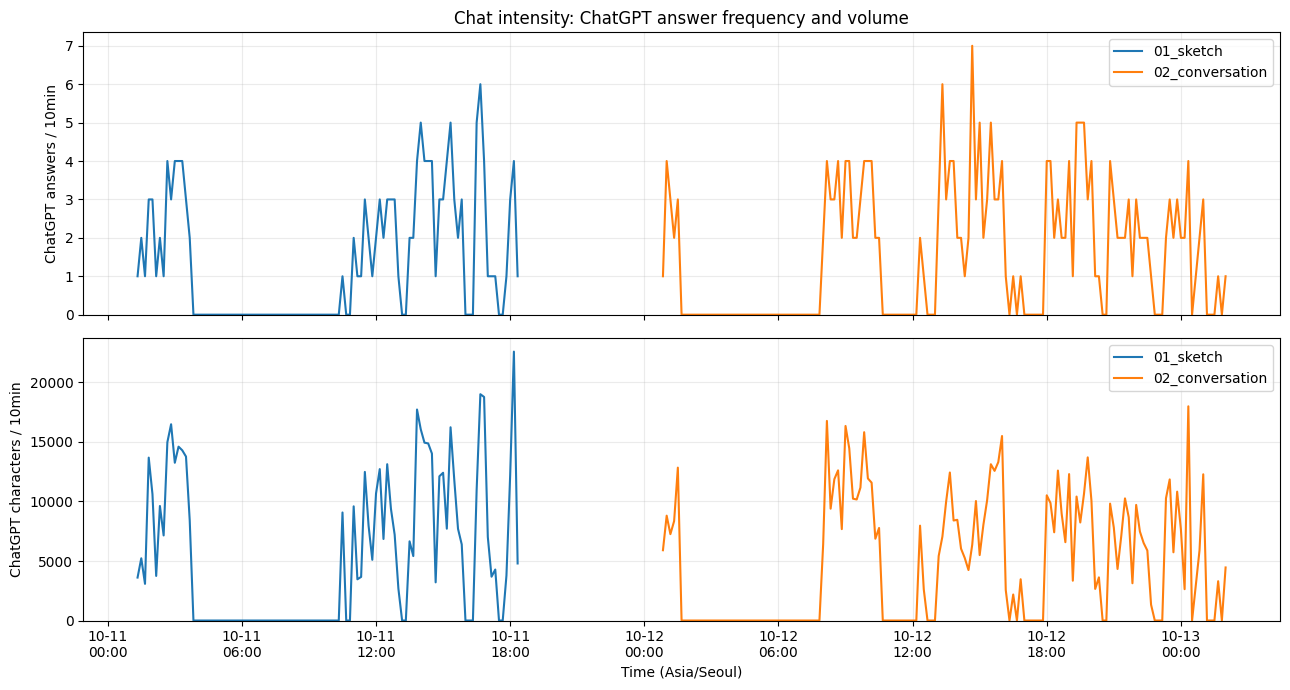

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for name, series in activity.items():
    axes[0].plot(series.index, series["messages"], label=name, linewidth=1.5)
    axes[1].plot(series.index, series["characters"], label=name, linewidth=1.5)

axes[0].set_ylabel(f"ChatGPT answers / {BIN}")
axes[1].set_ylabel(f"ChatGPT characters / {BIN}")
axes[0].set_title("Chat intensity: ChatGPT answer frequency and volume")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend()

axes[1].xaxis.set_major_locator(
    mdates.AutoDateLocator(minticks=6, maxticks=12, tz=ZoneInfo(TIMEZONE))
)
axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%m-%d\n%H:%M", tz=ZoneInfo(TIMEZONE))
)
axes[1].set_xlabel(f"Time ({TIMEZONE})")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "chat_intensity.png", dpi=180, bbox_inches="tight")
plt.show()